*Analysis of OCR Models on the ClinOCR dataset*

In [ ]:
'''
Models included in the report :
Traditional OCR models - DocTR,EasyOCR,PPOCR v6,Tesseract
Transformer based OCR models - TrOCR, SuryaOCR, Docling, Nougat
Vision Language Models (OCR specialized) - DotsOCR, Hunyuan OCR, Qwen2.5-VL-3B-Instruct, DeepSeek OCR, MinerU2.5, GotOCR 2.0,
DeepSeek2, OlmOCR2, Chandra2, Unlimited OCR
General Vision Language Models - Florence 2, InternVL2-1B, PaddleOCR-VL-1.5

For each model, the raw output has been saved (.json/.txt) while the plain text prediction and the runtimes have been stored as csvs. Performance has been compared on the
normalized text prediction using several metrics (CER/WER).'''


'\nModels included in the report :\nTraditional OCR models - DocTR,EasyOCR,PPOCR v6,Tesseract\nTransformer based OCR models - TrOCR, SuryaOCR, Docling, Nougat\nVision Language Models (OCR specialized) - DotsOCR, Hunyuan OCR, Qwen2.5-VL-3B-Instruct, DeepSeek OCR, MinerU2.5, GotOCR 2.0,\nDeepSeek2, OlmOCR2, Chandra2, Unlimited OCR\nGeneral Vision Language Models - Florence 2, InternVL2-1B, PaddleOCR-VL-1.5\n\nFor each model, the raw output has been saved (.json/.txt) while the plain text prediction and the runtimes have been stored as csvs. Performance has been compared on the\nnormalized text prediction using several metrics (CER/WER).'

In [ ]:
!pip install jiwer
!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 56.3 MB/s eta 0:00:00


In [ ]:
#Importing all basic libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from jiwer import wer
from rapidfuzz.distance import Levenshtein
from sklearn.metrics import confusion_matrix

Metrics Calculations

In [ ]:
#Pre processing Functions
import re
def normalize_text(text):

    """
    Normalizes text for OCR evaluation.
    - Replaces tabs/newlines with spaces
    - Collapses multiple spaces
    - Strips leading/trailing whitespace
    """

    if text is None:
        return ""

    text = str(text)

    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")
    text = text.replace("\t", " ")
    text = text.replace("\n", " ")

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
def character_error_rate(ground_truth, prediction):

    """
    Computes Character Error Rate (CER).
    Lower is better.
    """

    gt = normalize_text(ground_truth)
    pred = normalize_text(prediction)

    if len(gt) == 0:
        return 0.0 if len(pred) == 0 else 1.0

    return Levenshtein.distance(gt, pred) / len(gt)

In [ ]:
def word_error_rate(ground_truth, prediction):

    """
    Compute Word Error Rate (WER).
    Lower is better.
    """

    gt = normalize_text(ground_truth)
    pred = normalize_text(prediction)

    return wer(gt, pred)

In [ ]:
def normalized_edit_distance(ground_truth, prediction):

    """
    Compute Normalized Edit Distance (NED).
    Lower is better.
    Range: 0 (perfect match) to 1 (completely different).
    """

    gt = normalize_text(ground_truth)
    pred = normalize_text(prediction)

    max_len = max(len(gt), len(pred))

    if max_len == 0:
        return 0.0

    return Levenshtein.distance(gt, pred) / max_len

In [ ]:
def character_accuracy(ground_truth, prediction):

    """
    Compute character-level accuracy.
    Higher is better.
    """

    cer = character_error_rate(ground_truth, prediction)
    return max(0.0, 1 - cer)

In [ ]:
from rapidfuzz.distance import Levenshtein

def precision_recall_f1(ground_truth, prediction):

    """
    Compute character-level Precision, Recall and F1
    using Levenshtein edit operations.
    """

    gt = normalize_text(ground_truth)
    pred = normalize_text(prediction)
    if len(gt) == 0 and len(pred) == 0:
        return 1.0, 1.0, 1.0

    ops = Levenshtein.editops(gt, pred)

    insertions = sum(op.tag == "insert" for op in ops)
    deletions = sum(op.tag == "delete" for op in ops)
    substitutions = sum(op.tag == "replace" for op in ops)

    tp = len(gt) - deletions - substitutions

    fp = insertions + substitutions
    fn = deletions + substitutions

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    if precision + recall == 0:
        f1 = 0.0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    return precision, recall, f1

In [ ]:
def compute_all_metrics(ground_truth, prediction):

    """
    Compute all OCR evaluation metrics for one document.
    """

    precision, recall, f1 = precision_recall_f1(ground_truth,prediction)

    return {
        "CER": character_error_rate(ground_truth, prediction),
        "WER": word_error_rate(ground_truth, prediction),
        "NED": normalized_edit_distance(ground_truth, prediction),
        "Character Accuracy": character_accuracy(ground_truth, prediction),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1}

In [ ]:
import re

def clean_internvl(text):
    patterns = [
        r"^\s*(sure|certainly|of course|okay|ok)[!,]?\s*",
        r"^\s*here\s+is\s+(the\s+)?(text|ocr\s+result|extracted\s+text)(\s+from\s+the\s+document)?\s*:?\s*",
        r"^\s*(the\s+)?document\s+contains\s*:?\s*",
        r"^\s*-{3,}\s*"
    ]

    for pattern in patterns:
        text = re.sub(pattern, "", text, flags=re.IGNORECASE)
    # Remove any leading horizontal rules left behind
    text = re.sub(r"^\s*-+\s*", "", text)
    return text.strip()

def clean_nougat(text):

    # Remove bold/italic markers
    text = re.sub(r"\*\*", "", text)
    text = re.sub(r"(?<!\*)\*(?!\*)", "", text)

    # Remove Markdown headings
    text = re.sub(r"^\s*#{1,6}\s*", "", text, flags=re.MULTILINE)

    # Remove bullet markers
    text = re.sub(r"^\s*[-+]\s+", "", text, flags=re.MULTILINE)

    # Remove Markdown checkboxes
    text = re.sub(r"\[[ xX]\]\s*", "", text)

    # Remove LaTeX commands
    text = re.sub(r"\\[a-zA-Z]+\{.*?\}", "", text)

    # Remove inline/display math
    text = re.sub(r"\\\(.+?\\\)", "", text)
    text = re.sub(r"\\\[.+?\\\]", "", text)
    text = re.sub(r"\$.*?\$", "", text)

    # Remove LaTeX list parameters
    text = re.sub(r"\[(?:noitemsep|topsep|parsep|partopsep)[^\]]*\]", "", text)

    # Remove escaped braces/backslashes left behind
    text = text.replace("\\{", "{").replace("\\}", "}")
    text = text.replace("\\", "")

    # Collapse multiple blank lines
    text = re.sub(r"\n\s*\n+", "\n\n", text)

    # Collapse spaces
    text = re.sub(r"[ \t]+", " ", text)

    return text.strip()

In [ ]:
from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("/content")
all_dfs = []

for csv_file in RESULTS_DIR.glob("*_results.csv"):

    df = pd.read_csv(csv_file)
    df = df.rename(columns={
        "raw_output_file": "raw_output",
        "runtime_sec": "runtime"
    })

    cols_to_drop = ["image_name", "success", "error"]
    df = df.drop(columns=cols_to_drop, errors="ignore")

    if "Unnamed: 0" in df.columns:
        if df["Unnamed: 0"].notna().any():
            print(f"{csv_file.name}: Dropping 'Unnamed: 0'")
        df = df.drop(columns=["Unnamed: 0"])

    name = csv_file.stem.lower()

    if "internvl" in name:
        print(f"Cleaning InternVL output ({csv_file.name})")
        df["prediction"] = df["prediction"].fillna("").apply(clean_internvl)

    elif "nougat" in name:
        print(f"Cleaning Nougat output ({csv_file.name})")
        df["prediction"] = df["prediction"].fillna("").apply(clean_nougat)

    # <-- This should be outside the if/elif
    all_dfs.append(df)

final_df = pd.concat(all_dfs, ignore_index=True)

print(f"\nLoaded {len(all_dfs)} models")
print(f"Total rows: {len(final_df)}")

EasyOCR_results.csv: Dropping 'Unnamed: 0'
Cleaning InternVL output (internvl_results.csv)
Tesseract_results.csv: Dropping 'Unnamed: 0'
Cleaning Nougat output (Nougat_results.csv)

Loaded 19 models
Total rows: 3647


In [ ]:
import pandas as pd

# Load original dataset
original_df = pd.read_csv("/content/ClinOCR_Dataset.csv")

# Rows that need fixing
mask = final_df["model"].isin(["InternVL2-1B", "Nougat"])

# Columns to copy back from the original dataset
cols_to_add = [c for c in original_df.columns if c != "doc_id"]

# Merge only the affected rows
fixed = (
    final_df.loc[mask, ["doc_id"]]
    .merge(original_df[["doc_id"] + cols_to_add], on="doc_id", how="left")
)

# Copy the missing columns back
for col in cols_to_add:
    final_df.loc[mask, col] = fixed[col].values

print("Done!")

Done!


In [ ]:
final_df.head()
#Please note that the columns till hetero_id were taken directly from the clinOCR dataset. Three subsets had been taken - normal, handwriting and tables.

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id,raw_output,prediction,runtime,model
0,normal_t1_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"Patient Name: Doe, Jane Patient ID: JG05141985...",normal,1.0,1.0,NaN,NaN,normal_t1_s1.json,"Patient Name: Doe, Jane Patient ID: JG05141985...",3.199286,EasyOCR
1,normal_t2_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Lakewood Hospital - Pathology Pathology Report...,normal,2.0,1.0,NaN,NaN,normal_t2_s1.json,Lakewood Hospital\nPathology\nPathology Report...,3.569557,EasyOCR
2,normal_t3_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Riverside Hospital. 742 Evergreen Terrace Spri...,normal,3.0,1.0,NaN,NaN,normal_t3_s1.json,Riverside Hospital: 742 Evergreen Terrace Spri...,4.128617,EasyOCR
3,normal_t4_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,GENERALHOSPITAL\nHOSPITAL\nDate of Visit: 06/2...,normal,4.0,1.0,NaN,NaN,normal_t4_s1.json,Date of Visit: 06/21/2025\nTime of Visit: 10.3...,3.363859,EasyOCR
4,normal_t5_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"University Medical Center 456 Oak Avenue, Spri...",normal,5.0,1.0,NaN,NaN,normal_t5_s1.json,"University Medical Center 456 Qak Avenue,Sprin...",1.956096,EasyOCR


In [ ]:
final_df["model"].unique()

array(['EasyOCR', 'Docling', 'GOT-OCR2', 'PaddleOCR-VL-0.9B',
       'Florence-2-base', 'InternVL2-1B', 'MinerU2.5-1.2B',
       'DeepSeek-OCR-2', 'olmOCR-2', 'Unlimited-OCR', 'Tesseract',
       'DeepSeek-OCR-3B', 'DotsOCR', 'Chandra-OCR-2', 'HunyuanOCR',
       'Nougat', 'Surya OCR', 'docTR', 'PP-OCRv6'], dtype=object)

In [ ]:
evaluation_df = final_df[~(
        (final_df["model"] == "DeepSeek-OCR-3B") &
        (final_df["subset"].str.lower() != "normal")
    )
].copy()

architecture_map = { "Tesseract": "Traditional", "EasyOCR": "Traditional", "docTR": "Traditional", "Nougat": "Transformer", "Docling": "Transformer",
                    "Surya OCR":"Transformer", "PP-OCRv6": "Traditional", "PaddleOCR-VL-0.9B": "VLM", "GOT-OCR2": "VLM (OCR)", "DotsOCR": "VLM (OCR)",
                     "DeepSeek-OCR-3B": "VLM (OCR)", "MinerU2.5-1.2B": "VLM (OCR)", "HunyuanOCR": "VLM (OCR)", "Florence-2-base": "VLM",
                     "qwen2.5-vl-3b-instruct": "VLM", "InternVL2-1B": "VLM", "Chandra-OCR-2": "VLM (OCR)", "DeepSeek-OCR-2" : "VLM (OCR)",
                     "olmOCR-2": "VLM (OCR)", "Unlimited-OCR": "VLM (OCR)"}
# Computing the metrics for normalized ground truth and prediction columns. metrics = []
metrics = []

for _, row in evaluation_df.iterrows():

    gt = normalize_text(row["ground_truth"])
    pred = normalize_text(row["prediction"])

    metric_dict = compute_all_metrics(gt, pred)

    metrics.append({
        "Model": row["model"],
        "Architecture": architecture_map.get(row["model"], "Unknown"),
        "Ground Truth": gt,
        "Prediction": pred,
        "runtime": row["runtime"],
        "subset": row["subset"],
        "doc_id": row["doc_id"],
        **metric_dict
    })

metrics_df = pd.DataFrame(metrics)

Visualizing and Analysing the Results

In [ ]:
leaderboard = (metrics_df.groupby("Model", as_index = False).agg({"CER": "mean","NED": "mean","WER": "mean","Character Accuracy": "mean","Precision": "mean",
"Recall": "mean","F1 Score": "mean",}).sort_values("CER"))
leaderboard

,Model,CER,NED,WER,Character Accuracy,Precision,Recall,F1 Score
2,DeepSeek-OCR-3B,0.127553,0.121670,0.162271,0.872447,0.954705,0.910001,0.929495
12,PP-OCRv6,0.246985,0.246985,0.665494,0.753015,0.900529,0.779372,0.827272
17,docTR,0.251144,0.251050,0.337824,0.748856,0.887038,0.774606,0.809272
14,Surya OCR,0.278318,0.275218,0.396723,0.721682,0.822534,0.776874,0.791720
5,EasyOCR,0.279218,0.279137,0.415883,0.720782,0.822899,0.757773,0.782890
15,Tesseract,0.305946,0.304151,0.434254,0.694054,0.834646,0.732177,0.767970
16,Unlimited-OCR,0.394204,0.238174,0.328696,0.639937,0.778435,0.929240,0.832298
8,HunyuanOCR,0.396174,0.277920,0.367029,0.627427,0.789702,0.855547,0.805555
13,PaddleOCR-VL-0.9B,0.439536,0.265282,0.341335,0.607391,0.760989,0.919878,0.816566
6,Florence-2-base,0.452633,0.421517,0.812674,0.564584,0.710038,0.617854,0.655499


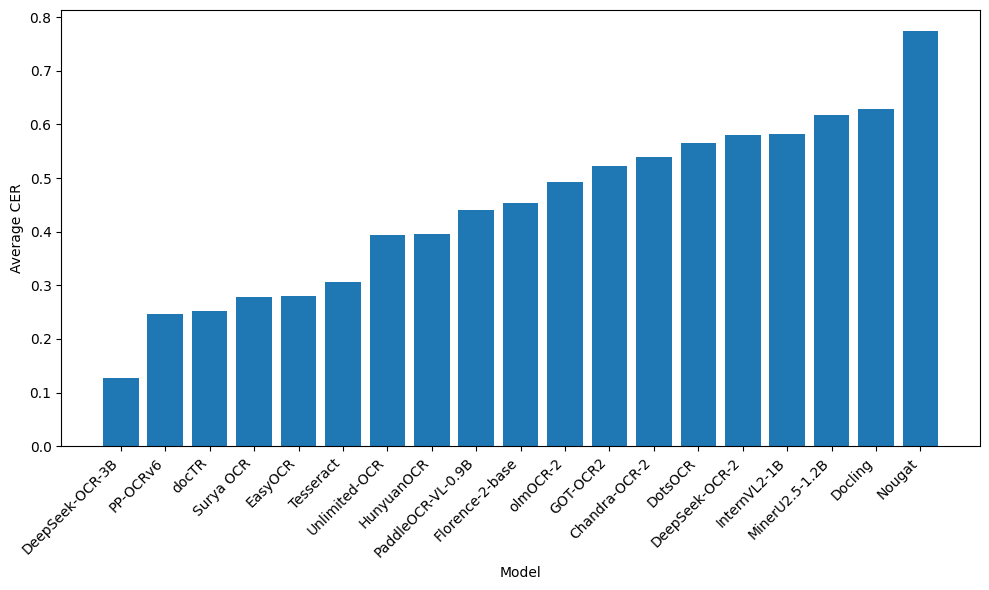

In [ ]:
#CER Values for all models
plt.figure(figsize=(10, 6))

plt.bar(leaderboard["Model"], leaderboard["CER"])

plt.xlabel("Model")
plt.ylabel("Average CER")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
summary = (metrics_df.groupby(["Model", "Architecture"], as_index=False).agg({"CER":"mean","WER":"mean","NED":"mean","Character Accuracy":"mean","F1 Score":"mean",
                                                                              "runtime":"mean"}))

In [ ]:
plot_df = summary.copy()
metrics = ["CER", "WER", "Character Accuracy", "F1 Score"]

for metric in metrics:
  plot_df[metric] = (plot_df[metric] - plot_df[metric].min()) / (plot_df[metric].max() - plot_df[metric].min())
plot_df = plot_df[~plot_df["Model"].isin(["Nougat", "InternVL2-1B"])]
plot_df = plot_df.sort_values("CER")

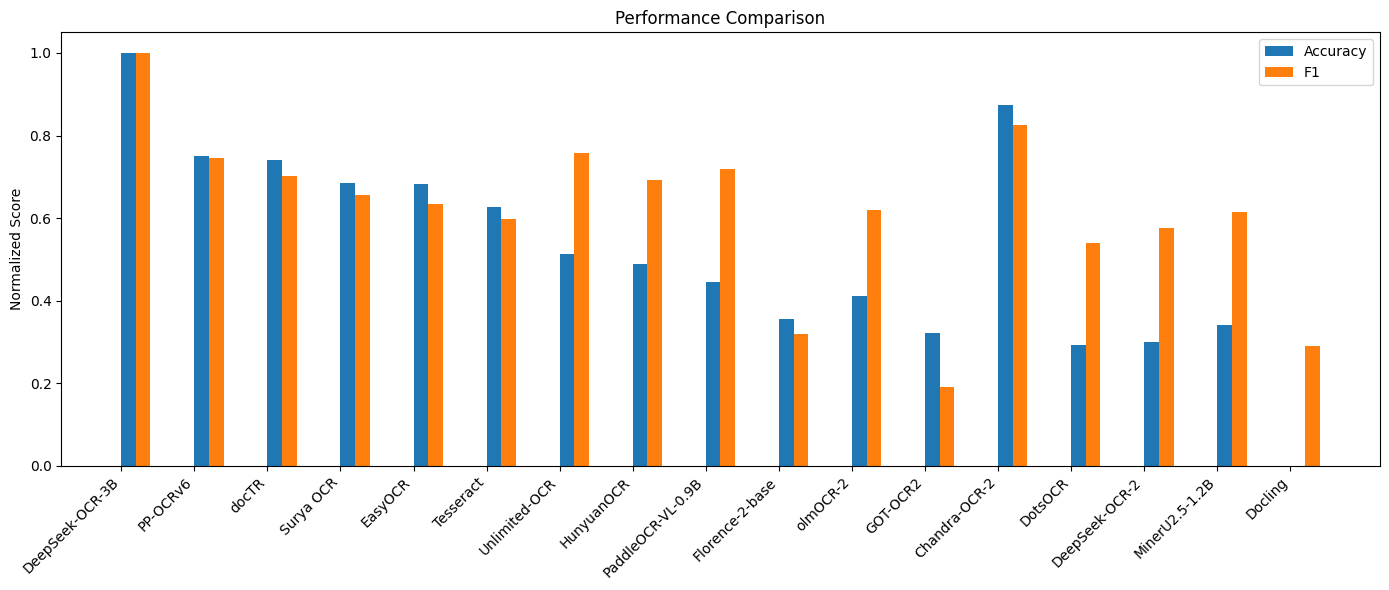

In [ ]:
#Bar chart for Accuracy and F1 scores
x = range(len(plot_df))
w = 0.2

plt.figure(figsize=(14,6))
plt.bar([i+0.5*w for i in x], plot_df["Character Accuracy"], width=w, label="Accuracy")
plt.bar([i+1.5*w for i in x], plot_df["F1 Score"], width=w, label="F1")

plt.xticks(x, plot_df["Model"], rotation=45, ha="right")

plt.ylabel("Normalized Score")
plt.title("Performance Comparison")
plt.legend()

plt.tight_layout()
plt.show()

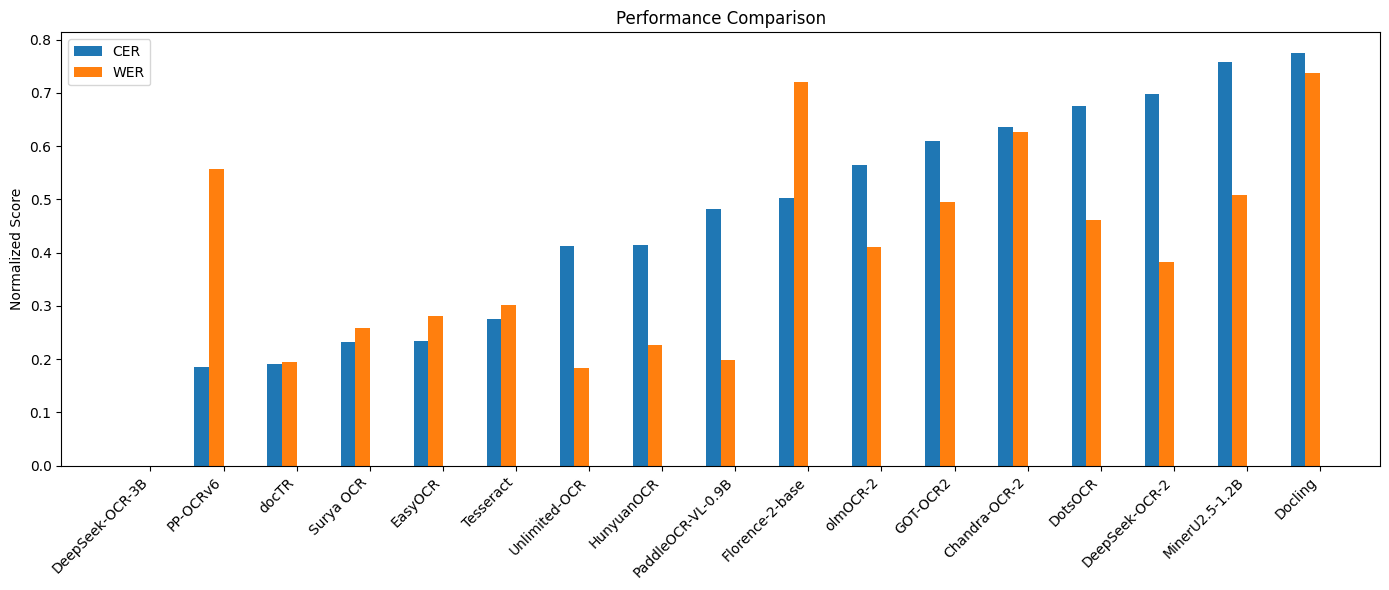

In [ ]:
#Bar chart for CER and WER scores
x = range(len(plot_df))
w = 0.2

plt.figure(figsize=(14,6))
plt.bar([i-1.5*w for i in x], plot_df["CER"], width=w, label="CER")
plt.bar([i-0.5*w for i in x], plot_df["WER"], width=w, label="WER")

plt.xticks(x, plot_df["Model"], rotation=45, ha="right")

plt.ylabel("Normalized Score")
plt.title("Performance Comparison")
plt.legend()

plt.tight_layout()
plt.show()

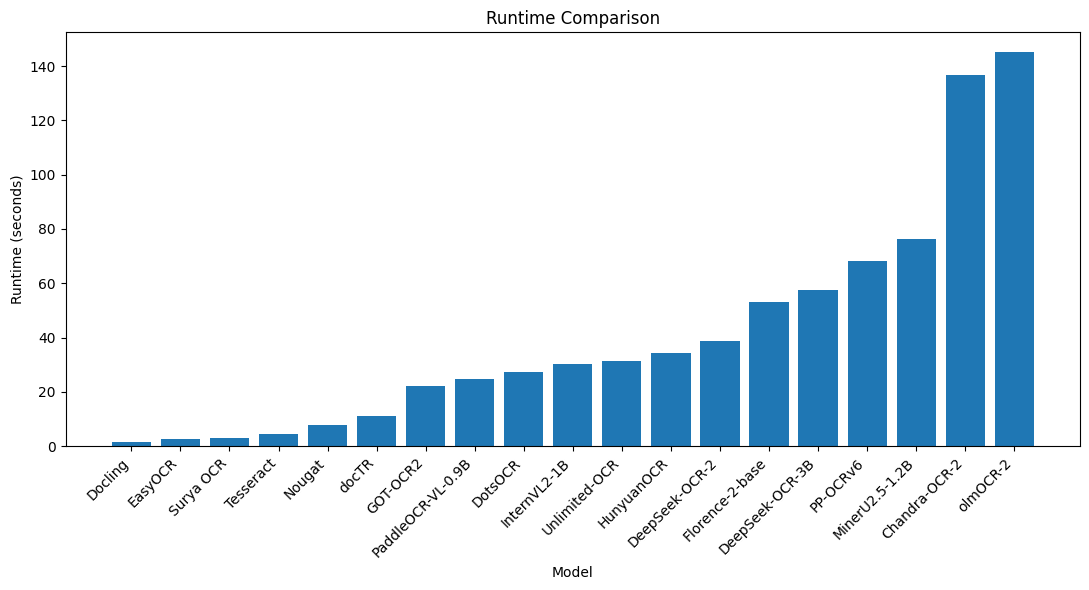

In [ ]:
#Comparison of runtimes for all models
plot_df = summary.sort_values("runtime")

plt.figure(figsize=(11,6))

plt.bar(plot_df["Model"], plot_df["runtime"])

plt.xlabel("Model")
plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

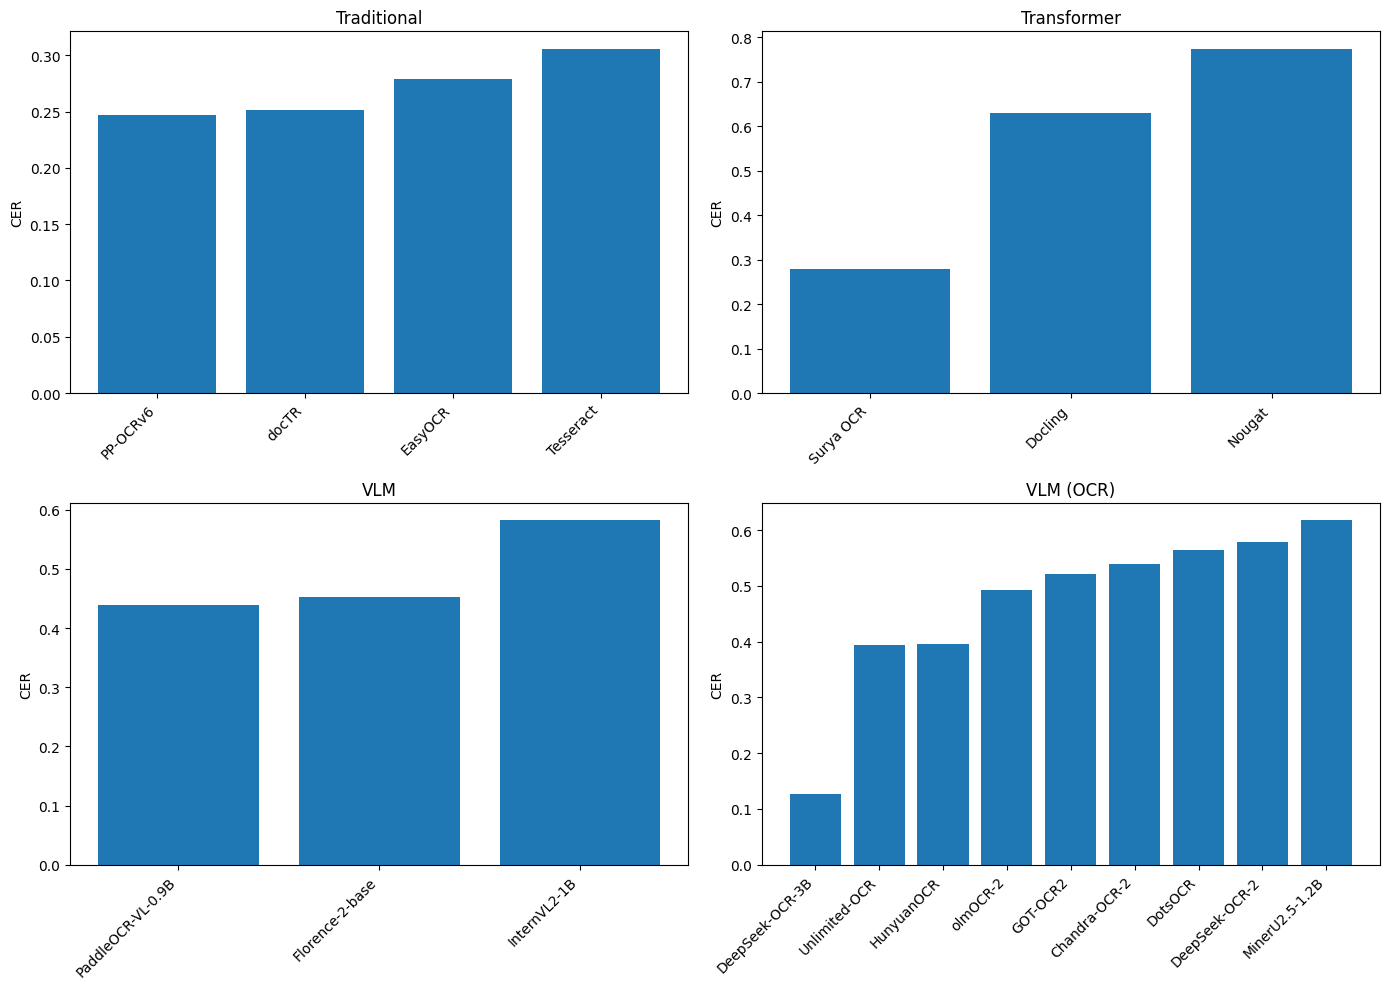

In [ ]:
#architecture wise CER scores comparison
architectures = ["Traditional","Transformer","VLM","VLM (OCR)"]
plt.figure(figsize=(14,10))

for i, arch in enumerate(architectures):
    plt.subplot(2,2,i+1)

    temp = summary[summary["Architecture"]==arch].sort_values("CER")
    plt.bar(temp["Model"], temp["CER"])
    plt.title(arch)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("CER")

plt.tight_layout()
plt.show()

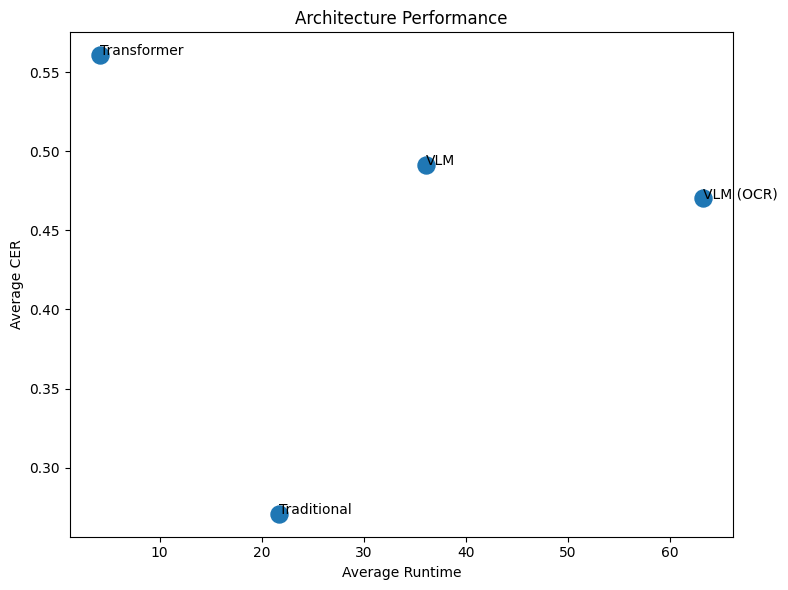

In [ ]:
#architecture vs performance
arch = (summary.groupby("Architecture", as_index=False).agg({"CER":"mean","runtime":"mean"}))
plt.figure(figsize=(8,6))

plt.scatter(arch["runtime"],arch["CER"],s=150)
for i in range(len(arch)):

    plt.text(arch.loc[i,"runtime"],arch.loc[i,"CER"],arch.loc[i,"Architecture"])

plt.xlabel("Average Runtime")
plt.ylabel("Average CER")
plt.title("Architecture Performance")

plt.tight_layout()
plt.show()

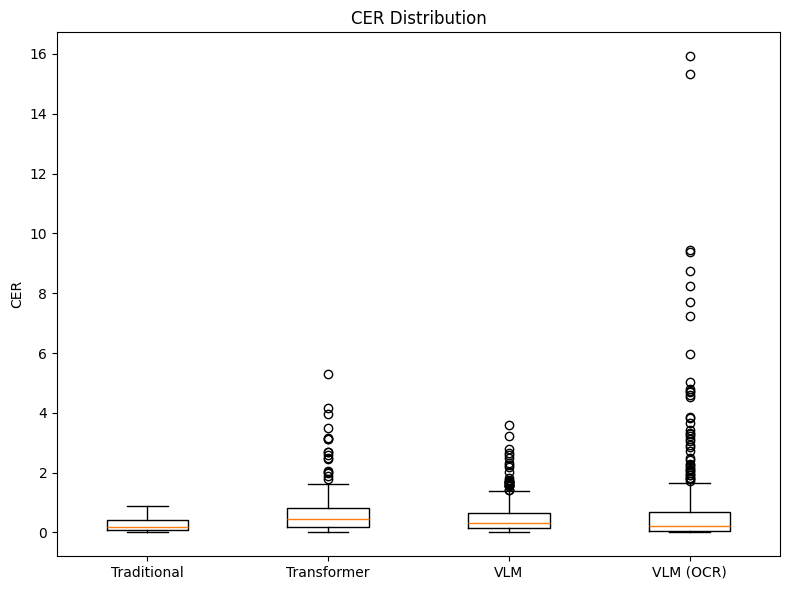

In [ ]:
#CER boxplots
groups = []
labels = []

for arch in architectures:
    groups.append(metrics_df[metrics_df["Architecture"]==arch]["CER"])
    labels.append(arch)

plt.figure(figsize=(8,6))

plt.boxplot(groups, tick_labels=labels)

plt.ylabel("CER")
plt.title("CER Distribution")

plt.tight_layout()
plt.show()

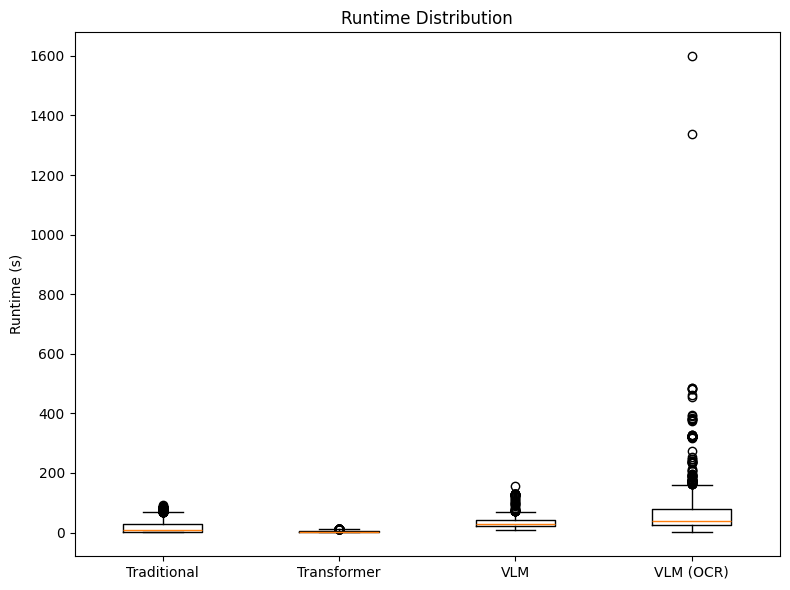

In [ ]:
#Runtime Boxplot
groups = []
labels = []

for arch in architectures:
    groups.append(metrics_df[metrics_df["Architecture"]==arch]["runtime"])
    labels.append(arch)

plt.figure(figsize=(8,6))
plt.boxplot(groups, tick_labels=labels)

plt.ylabel("Runtime (s)")
plt.title("Runtime Distribution")

plt.tight_layout()
plt.show()

In [ ]:
metrics_df["Doc Length"] = metrics_df["Ground Truth"].str.len()

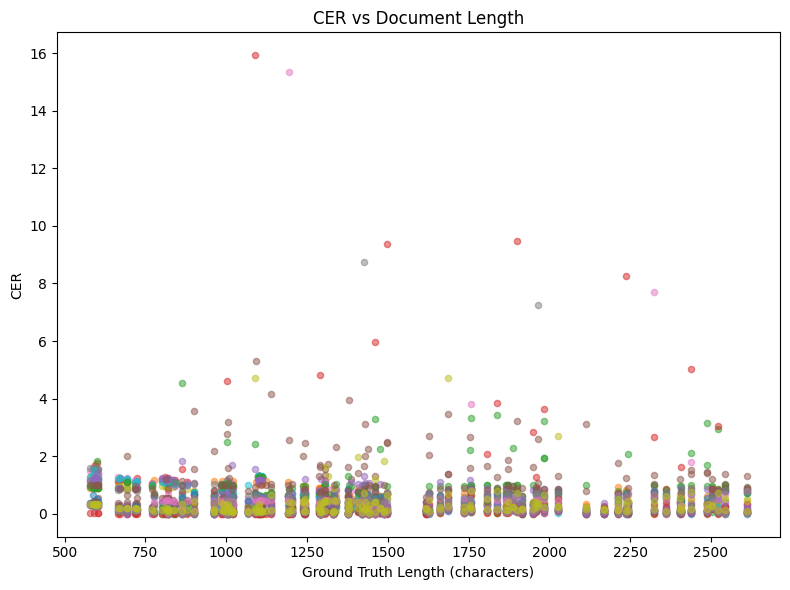

In [ ]:
plt.figure(figsize=(8,6))
for model in metrics_df["Model"].unique():
    temp = metrics_df[metrics_df["Model"] == model]

    plt.scatter(
        temp["Doc Length"],
        temp["CER"],
        alpha=0.5,
        s=20,
        label=model
    )

plt.xlabel("Ground Truth Length (characters)")
plt.ylabel("CER")
plt.title("CER vs Document Length")

plt.tight_layout()
plt.show()

/tmp/ipykernel_2197/2590438355.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp["Length Bin"] = pd.cut(temp["Doc Length"],bins=5)


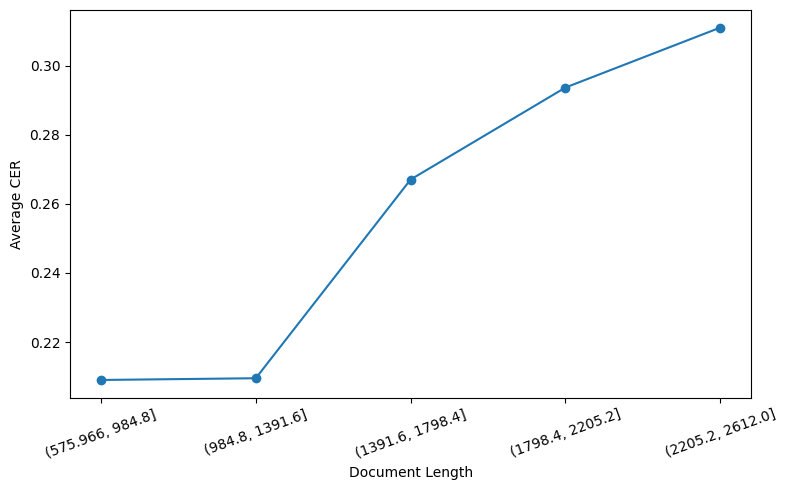

In [ ]:
temp["Length Bin"] = pd.cut(temp["Doc Length"],bins=5)
plot = (temp.groupby("Length Bin", observed=False)["CER"].mean())
plt.figure(figsize=(8,5))
plt.plot(range(len(plot)),plot.values,marker="o")

plt.xticks(range(len(plot)), plot.index, rotation=20)

plt.xlabel("Document Length")
plt.ylabel("Average CER")

plt.tight_layout()
plt.show()

In [ ]:
best = (metrics_df.loc[metrics_df.groupby("doc_id")["CER"].idxmin()])
win_counts = (best["Model"].value_counts().sort_values(ascending=False))

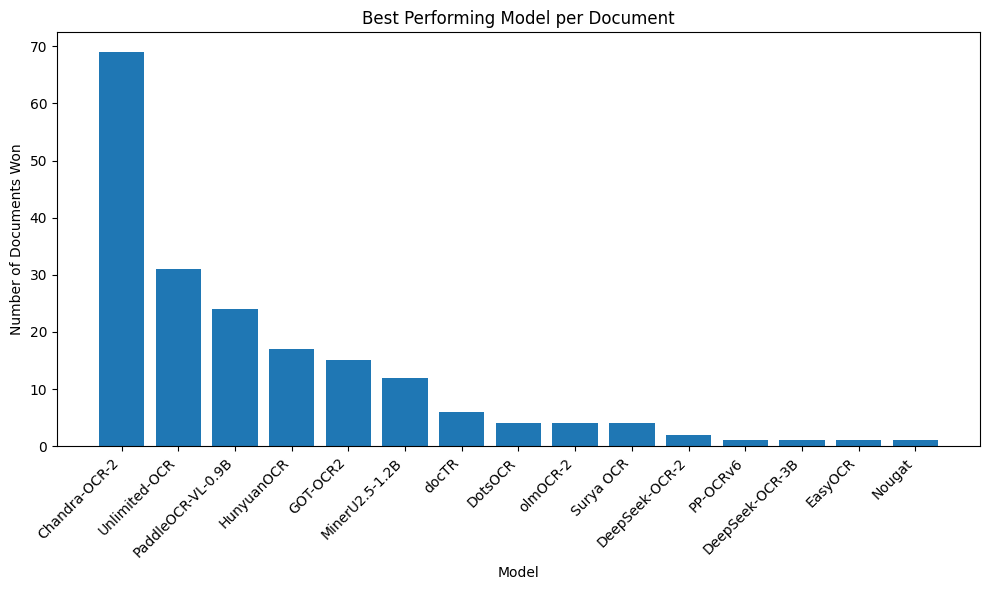

In [ ]:
plt.figure(figsize=(10,6))
plt.bar(win_counts.index, win_counts.values)
plt.xticks(rotation=45, ha="right")

plt.xlabel("Model")
plt.ylabel("Number of Documents Won")
plt.title("Best Performing Model per Document")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

models = sorted(metrics_df["Model"].unique())

wins = pd.DataFrame(
    0,
    index=models,
    columns=models,
    dtype=float
)

documents = metrics_df["doc_id"].unique()

for m1 in models:
    for m2 in models:

        if m1 == m2:
            continue

        total = 0
        better = 0

        for doc in documents:

            temp = metrics_df[
                metrics_df["doc_id"] == doc
            ]

            row1 = temp[temp["Model"] == m1]
            row2 = temp[temp["Model"] == m2]

            if len(row1) == 0 or len(row2) == 0:
                continue

            total += 1

            if row1["CER"].values[0] < row2["CER"].values[0]:
                better += 1

        wins.loc[m1, m2] = 100 * better / total

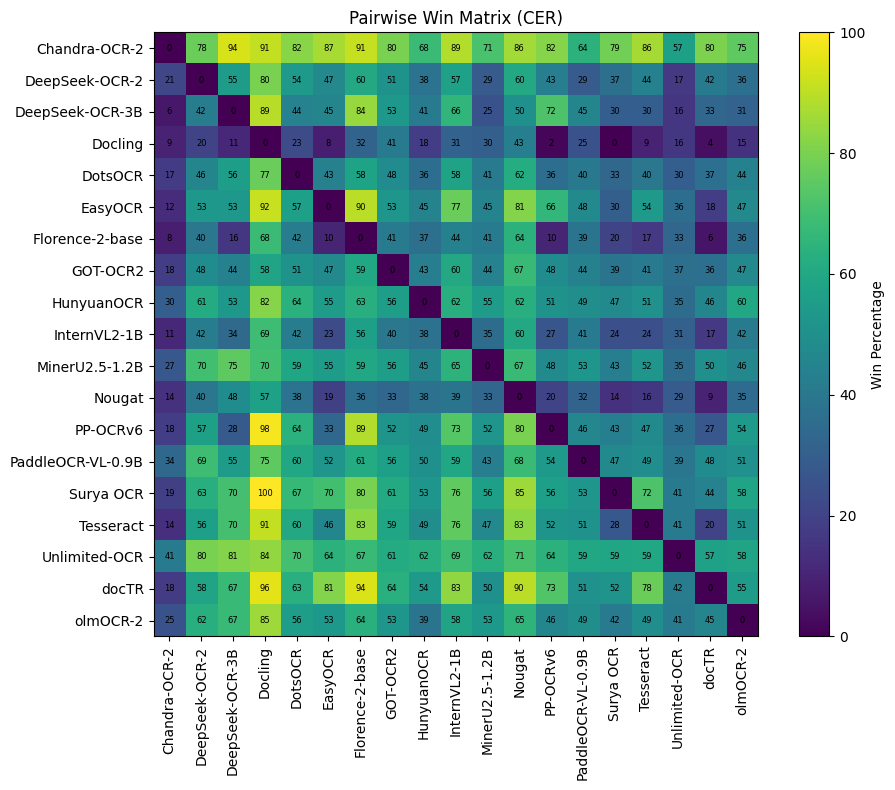

In [ ]:
plt.figure(figsize=(10,8))

plt.imshow(wins, vmin=0, vmax=100)

plt.xticks(
    range(len(models)),
    models,
    rotation=90
)

plt.yticks(
    range(len(models)),
    models
)

plt.colorbar(label="Win Percentage")

for i in range(len(models)):
    for j in range(len(models)):
        plt.text(
            j,
            i,
            f"{wins.iloc[i,j]:.0f}",
            ha="center",
            va="center",
            fontsize=6
        )

plt.title("Pairwise Win Matrix (CER)")

plt.tight_layout()
plt.show()

In [ ]:
plot = (metrics_df.groupby(["Model", "subset"], as_index=False)["CER"].mean())

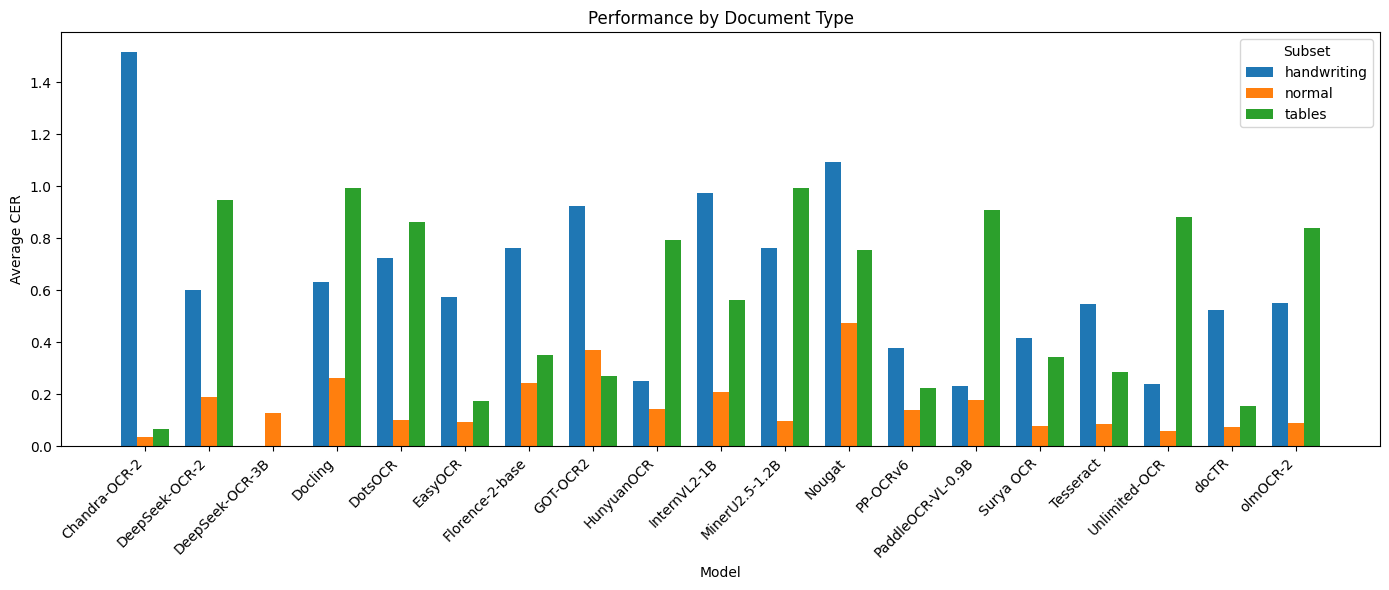

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

models = plot["Model"].unique()
subsets = plot["subset"].unique()

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14,6))

for i, subset in enumerate(subsets):

    temp = (
        plot[plot["subset"] == subset]
        .set_index("Model")
        .reindex(models)
    )

    plt.bar(
        x + (i-1)*width,
        temp["CER"],
        width,
        label=subset
    )

plt.xticks(x, models, rotation=45, ha="right")
plt.xlabel("Model")
plt.ylabel("Average CER")
plt.title("Performance by Document Type")
plt.legend(title="Subset")

plt.tight_layout()
plt.show()